## 1. Tree-Based Methods

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a)
Download the APS Failure data from: <https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks>. The dataset contains a training set and a test set. The training set contains 60,000 rows, of which 1,000 belong to the positive class and 171 columns, of which one is the class column. All attributes are numeric.

In [2]:
# load training and test sets
train_df = pd.read_csv("../data/Homework 6 Data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df = pd.read_csv("../data/Homework 6 Data/aps_failure_test_set.csv", skiprows=20, na_values="na")

train_df.shape, test_df.shape

((60000, 171), (16000, 171))

### (b)
**Data Preparation** This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea.

#### (b) 1.
Research what types of techniques are usually used for dealing with data with missing values. Pick at least one of them and apply it to this data in the next steps.

**b1 answer** 

Common techniques are deleting rows or columns with missing values, mean/median/mode imputation, KNN imputation, regression imputation, and adding missing-value indicators. Median imputation is used in this task.

In [3]:
# Separate features and labels
X_train = train_df.drop(columns="class")
y_train = train_df["class"]

X_test = test_df.drop(columns="class")
y_test = test_df["class"]

# Fill missing values with medians
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_test.median())

#### (b) 2.
For each of the 170 features, calculate the coefficient of variation $CV = \frac{s}{m}$, where $s$ is sample standard deviation and $m$ is sample mean.

In [4]:
#Compute the coefficient 
cv = X_train.std() / X_train.mean()
cv.sort_values(ascending=False)

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64

#### (b) 3.
Plot a correlation matrix for your features using pandas or any other tool.

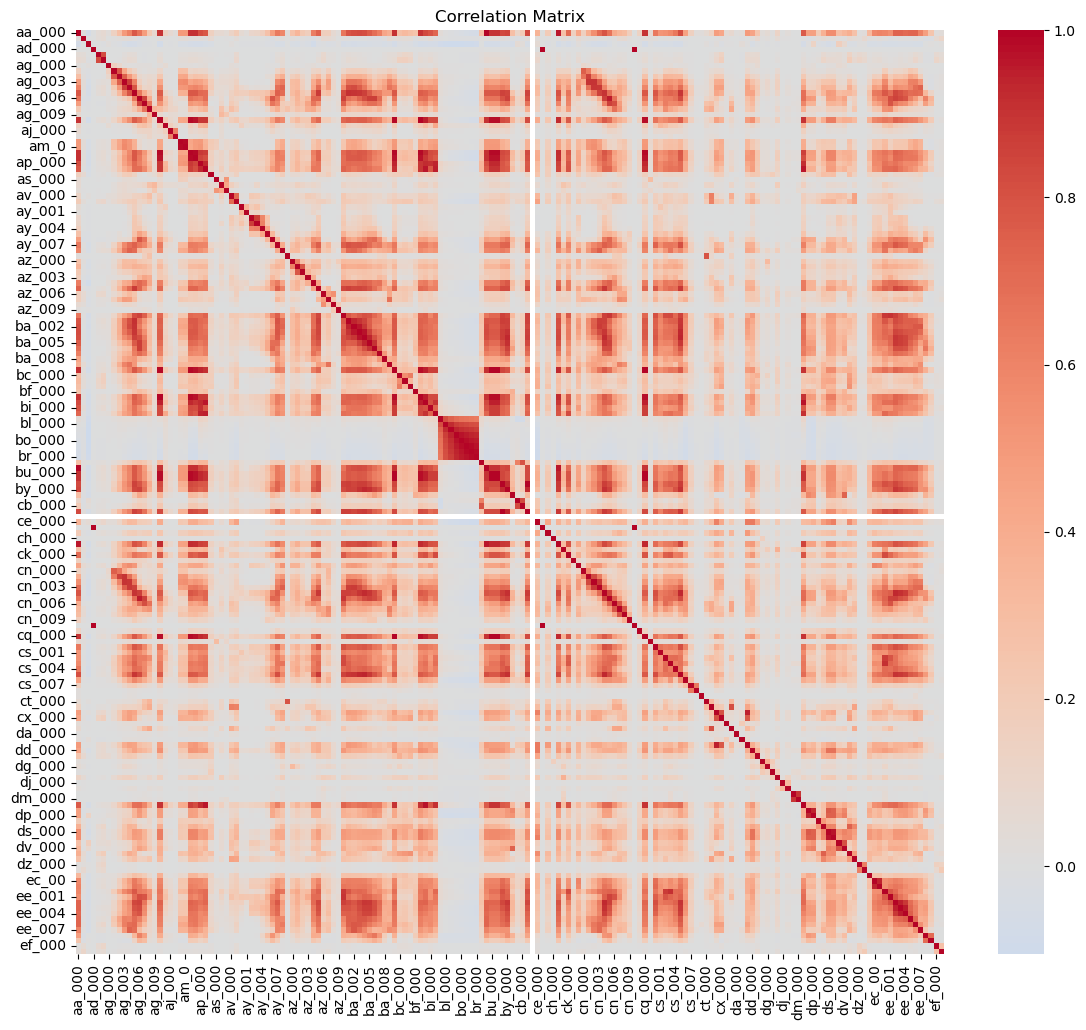

In [5]:
# Compute the correlation matrix
corr = X_train.corr()

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr,cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix")
plt.show()

#### (b) 4.
Pick $\lfloor\sqrt{170}\rfloor$ features with highest $CV$, and make scatter plots and box plots for them, similar to those on p. 129 of ISLR. Can you draw conclusions about significance of those features, just by the scatter plots? This does not mean that you will only use those features in the following questions. We picked them only for visualization.

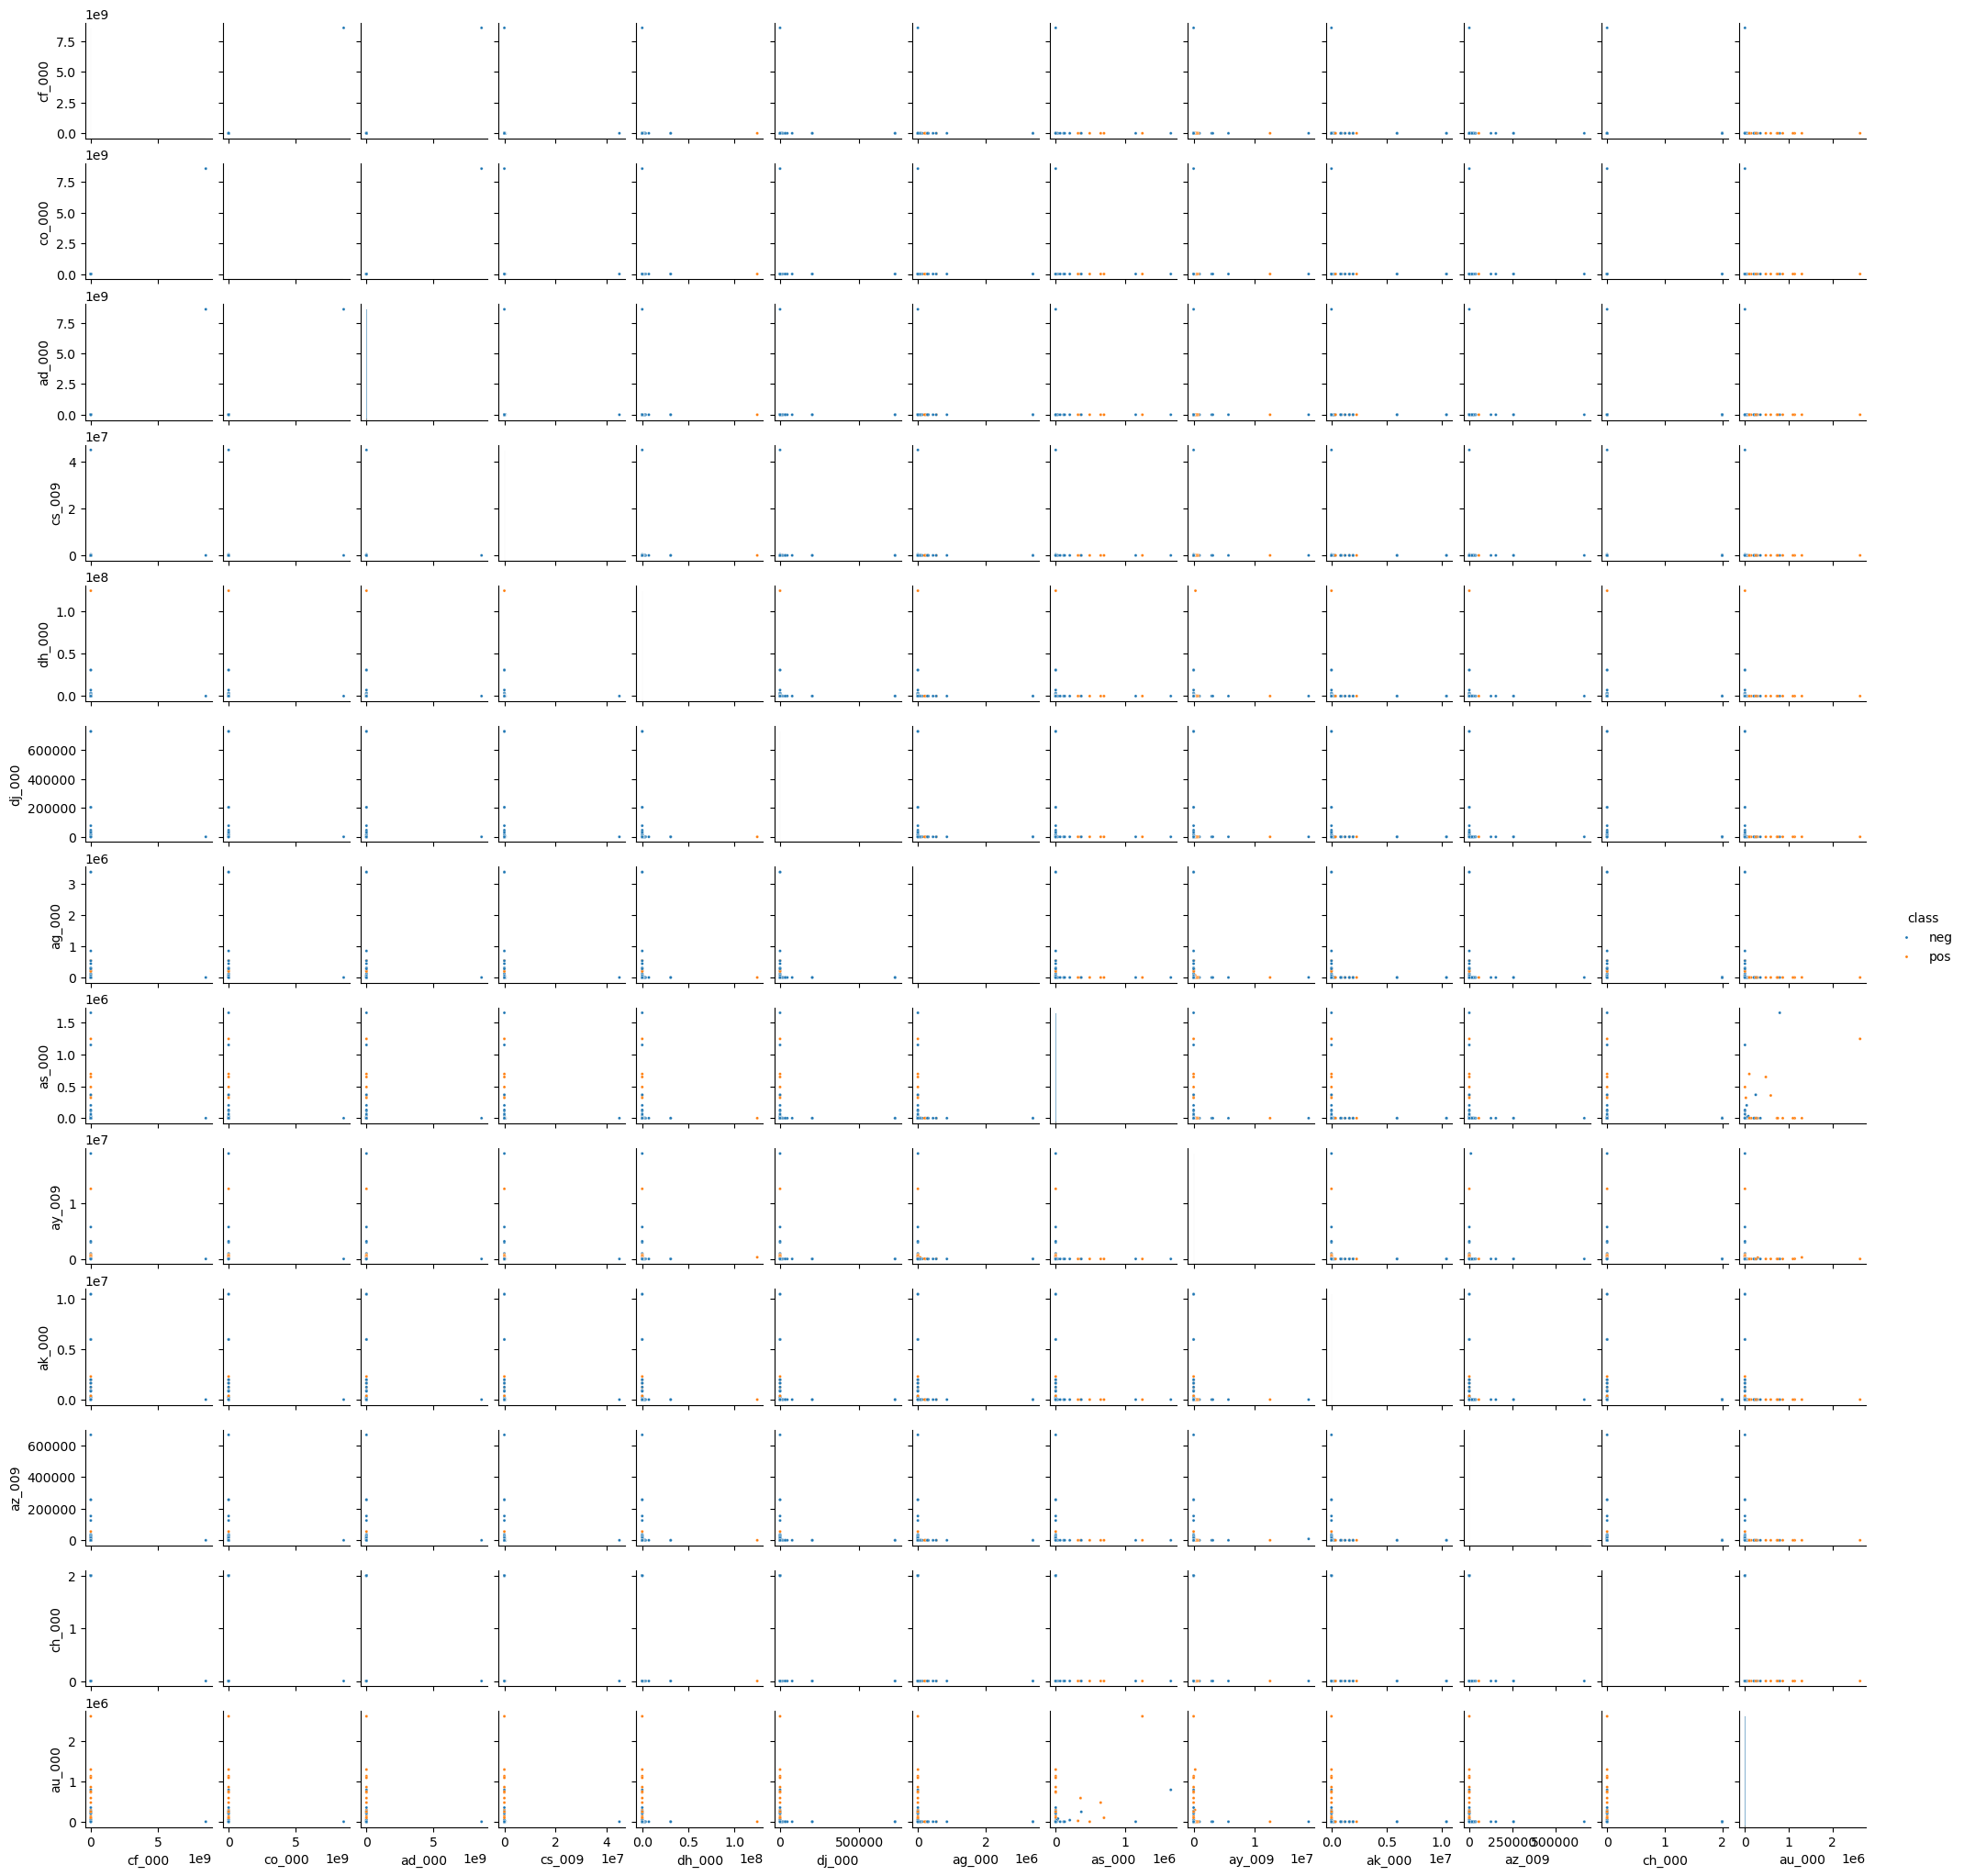

In [6]:
# Pick 13 features with  highest CV
n_top = math.isqrt(X_train.shape[1])
top_features = cv.sort_values(ascending=False).index[:n_top]

# Make scatter plots 
plot_df = X_train[top_features].copy()
plot_df["class"] = y_train
sns.pairplot(plot_df, hue="class",diag_kind="hist", height=1.6, plot_kws={"s": 5})
plt.show()

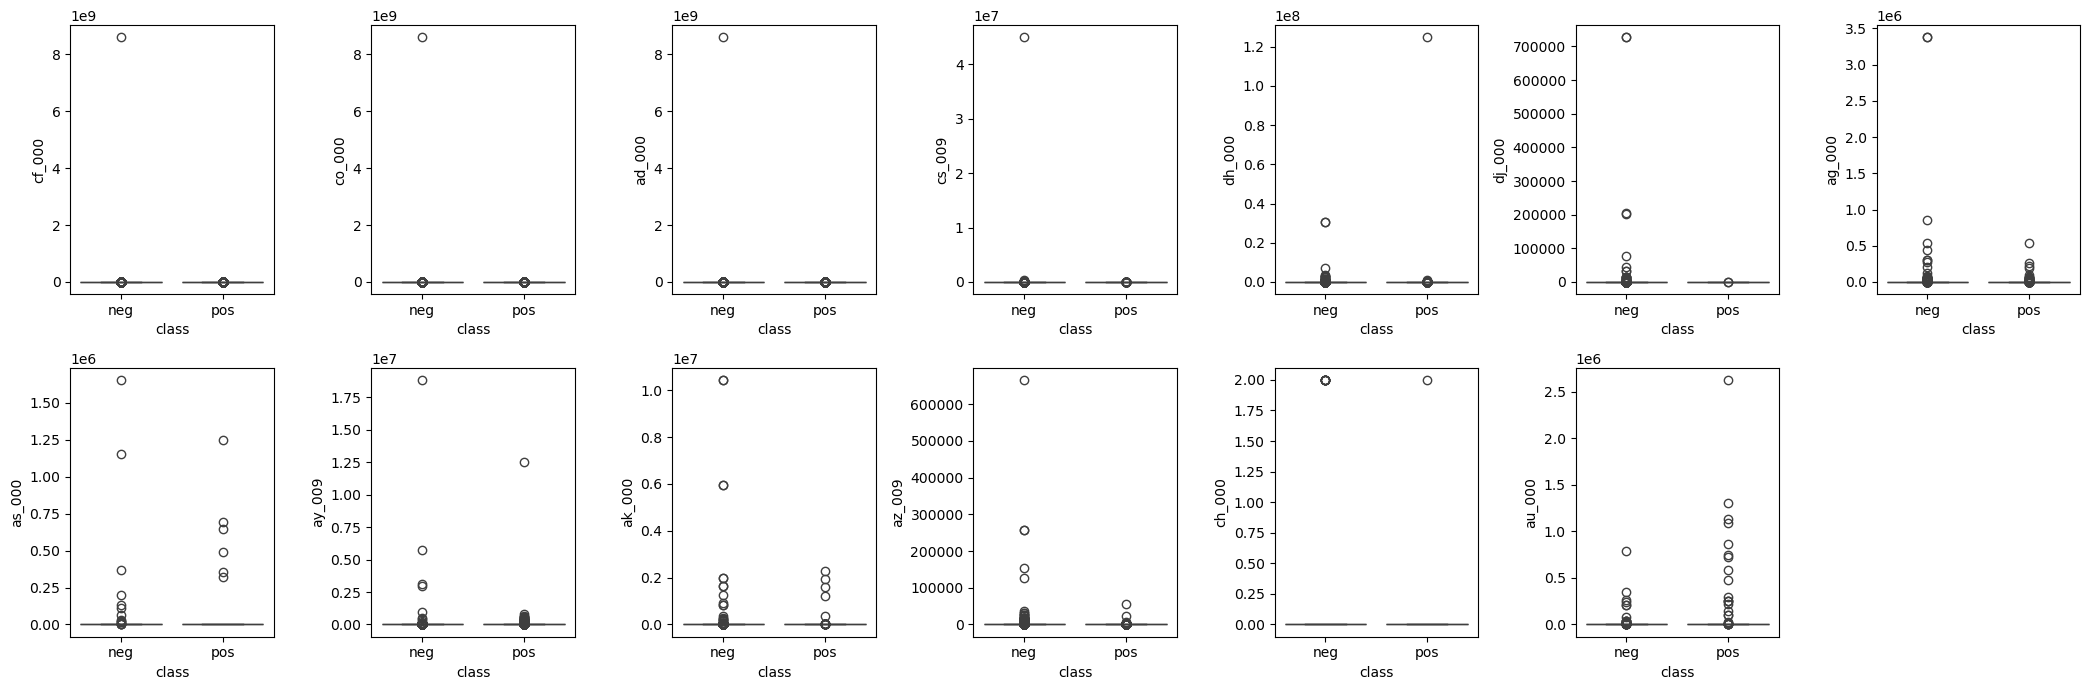

In [7]:
# Make a box plot of each top feature grouped by class
fig, axes = plt.subplots(2, 7, figsize=(21, 7))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=plot_df, x="class", y=feature, ax=ax)
# Remove the unused subplot
axes.flat[-1].remove()
plt.tight_layout()
plt.show()

**b4 answer** 

We can't draw conclusions about significance of those features just by the scatter plots. Most points are near zero and two classes overlap heavily.

#### (b) 5.
Determine the number of positive and negative data. Is this data set imbalanced?

In [8]:
y_train.value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

**b5 answer** 

There are 59,000 negative samples and 1,000 positive samples, so the data set is imbalanced.

### (c)
Train a random forest to classify the data set. Do NOT compensate for class imbalance in the data set. Calculate the confusion matrix, ROC, AUC, and misclassification for training and test sets and report them (You may use pROC package). Calculate Out of Bag error estimate for your random forest and compare it to the test error.

In [9]:
# report confusion matrix, AUC and misclassification, and plot ROC 
def evaluate(model, y_train, y_test):
    fig, ax = plt.subplots(figsize=(6, 5))
    for name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        # Predict labels and probabilities of the positive class (column 1 is the positive class)
        y_pred = model.predict(X)
        y_score = model.predict_proba(X)[:, 1]

        # Confusion matrix
        cm = confusion_matrix(y, y_pred, labels=model.classes_)
        cm_df = pd.DataFrame(cm, index=["true neg", "true pos"], columns=["pred neg", "pred pos"])

        # ROC and AUC
        fpr, tpr, _ = roc_curve(y, y_score, pos_label=model.classes_[1])
        roc_auc = auc(fpr, tpr)

        # Misclassification rate
        misclass = (y_pred != y).mean()

        # Report results
        print(f"{name} confusion matrix:")
        display(cm_df)
        print(f"{name} AUC: {roc_auc:.4f}, misclassification: {misclass:.4f}\n")
        ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

    # Finish the ROC plot
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curve")
    ax.legend()
    plt.show()

Train confusion matrix:


,pred neg,pred pos
true neg,59000,0
true pos,1,999


Train AUC: 1.0000, misclassification: 0.0000

Test confusion matrix:


,pred neg,pred pos
true neg,15610,15
true pos,106,269


Test AUC: 0.9928, misclassification: 0.0076



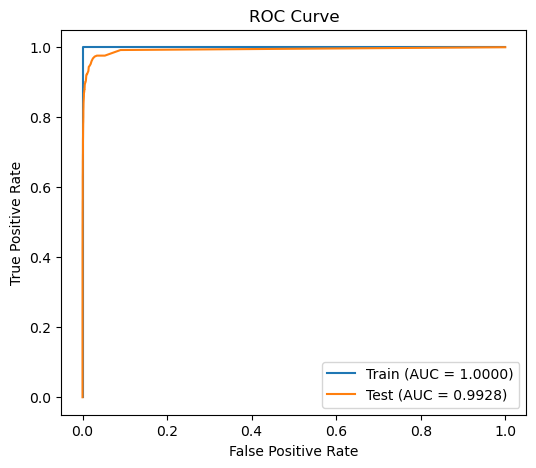

In [10]:
# Train the random forest
rf = RandomForestClassifier(oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Report results
evaluate(rf, y_train, y_test)

In [11]:
# the out-of-bag error
oob_error = 1 - rf.oob_score_
oob_error

0.006116666666666659

**c answer** 

The OOB error (0.0061) is close to the test error (0.0076).

### (d)
Research how class imbalance is addressed in random forests. Compensate for class imbalance in your random forest and repeat 1c. Compare the results with those of 1c.

Train confusion matrix:


,pred neg,pred pos
true neg,59000,0
true pos,1,999


Train AUC: 1.0000, misclassification: 0.0000

Test confusion matrix:


,pred neg,pred pos
true neg,15609,16
true pos,156,219


Test AUC: 0.9904, misclassification: 0.0107



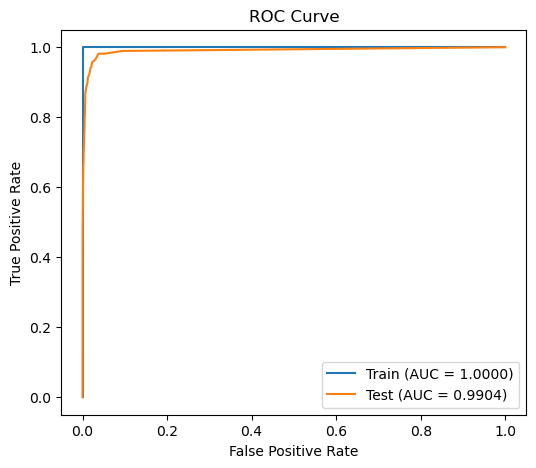

In [12]:
# Train a random forest with balanced class weights
rf_balanced = RandomForestClassifier(class_weight="balanced_subsample", oob_score=True, random_state=42, n_jobs=-1)
rf_balanced.fit(X_train, y_train)
# Report results
evaluate(rf_balanced, y_train, y_test)

In [13]:
# Compute the out-of-bag error
oob_error_balanced = 1 - rf_balanced.oob_score_
oob_error_balanced

0.007883333333333353

**d answer** 

Class imbalance in random forests is usually addressed by class weighting, balanced bootstrap sampling , or adjusting the decision threshold. We use class_weight="balanced_subsample" here.

Compared with 1c, the training results of the balanced forest are the almost same. On the test set, the balanced forest is slightly worse, AUC 0.9904 vs 0.9928, misclassification 0.0107 vs 0.0076. The OOB error of the balanced forest (0.0079) is lower than its test error (0.0107).

### (e)
**XGBoost and Model Trees** In the case of a univariate tree, only one input dimension is used at a tree split. In a multivariate tree, or model tree, at a decision node all input dimensions can be used and thus it is more general. In univariate classification trees, majority polling is used at each node to determine the split of that node as the decision rule. In model trees, a (linear) model that relies on all of the variables is used to determine the split of that node (i.e. instead of using $X_j > s$ as the decision rule, one has $\sum_j \beta_j X_j > s$ as the decision rule). Alternatively, in a regression tree, instead of using average in the region associated with each node, a linear regression model is used to determine the value associated with that node.

One of the methods that can be used at each node is Logistic Regression. Because the number of variables is large in this problem, one can use L1-penalized logistic regression at each node. You can use XGBoost to fit the model tree. Determine $\alpha$ (the regularization term) using cross-validation. Train the model for the APS data set without compensation for class imbalance. Use one of 5 fold, 10 fold, and leave-one-out cross validation methods to estimate the error of your trained model and compare it with the test error. Report the Confusion Matrix, ROC, and AUC for training and test sets.

In [14]:
# Convert class labels to 0/1
y_train_bin = (y_train == "pos").astype(int)
y_test_bin = (y_test == "pos").astype(int)

# Choose L1 penalty with 5-fold cross-validation
param_grid = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb = XGBClassifier(random_state=42)
xgb_search = GridSearchCV(xgb, param_grid, cv=cv_folds)
xgb_search.fit(X_train, y_train_bin)
xgb_search.best_params_

{'reg_alpha': 0.01}

In [15]:
# Estimate the error of the trained model with 5-fold cross-validation
cv_error = 1 - xgb_search.best_score_
cv_error

np.float64(0.006349999999999967)

Train confusion matrix:


,pred neg,pred pos
true neg,59000,0
true pos,1,999


Train AUC: 1.0000, misclassification: 0.0000

Test confusion matrix:


,pred neg,pred pos
true neg,15609,16
true pos,86,289


Test AUC: 0.9937, misclassification: 0.0064



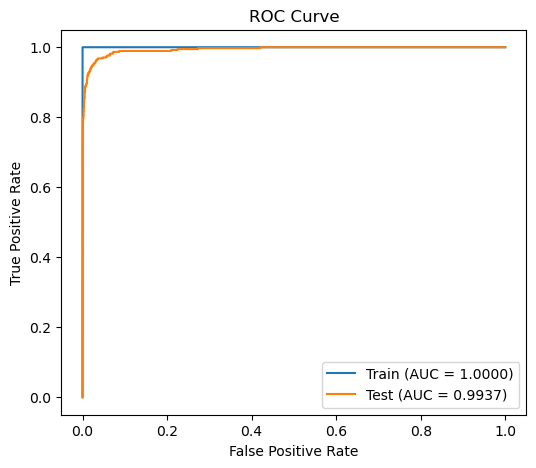

In [16]:
# Report results
evaluate(xgb_search.best_estimator_, y_train_bin, y_test_bin)

**e answer** 

The best $\alpha$ chosen by 5-fold cross-validation is 0.01. The 5-fold CV error (0.0063) is very close to the test error (0.0064).

### (f)
Use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process your data to compensate for class imbalance. Train XGBoost with L1-penalized logistic regression at each node using the pre-processed data and repeat 1e. Do not forget that there is a right and a wrong way of cross validation here. Compare the uncompensated case with SMOTE case.

In [17]:
# SMOTE is applied only to training folds during cross-validation
smote_xgb = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(random_state=42)),
])

# Choose L1 penalty with 5-fold 
smote_param = {"xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}
smote_search = GridSearchCV(smote_xgb, smote_param, cv=cv_folds)
smote_search.fit(X_train,y_train_bin)
smote_search.best_params_

{'xgb__reg_alpha': 1}

In [18]:
# Estimate the error of the trained model with 5-fold cross-validation
smote_cv_error = 1 - smote_search.best_score_
smote_cv_error

np.float64(0.006333333333333302)

Train confusion matrix:


,pred neg,pred pos
true neg,59000,0
true pos,1,999


Train AUC: 1.0000, misclassification: 0.0000

Test confusion matrix:


,pred neg,pred pos
true neg,15554,71
true pos,56,319


Test AUC: 0.9945, misclassification: 0.0079



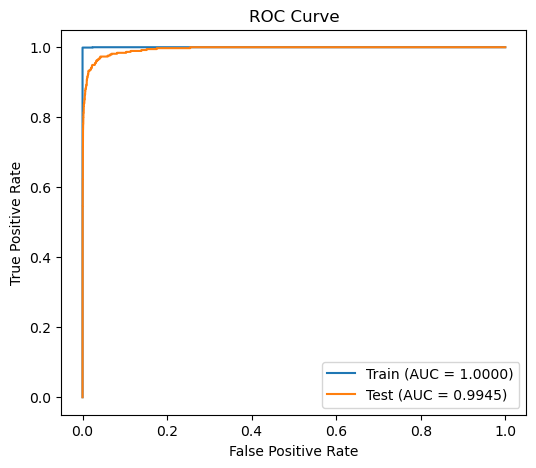

In [19]:
# Report results
evaluate(smote_search.best_estimator_, y_train_bin, y_test_bin)

**f answer** 

The best $\alpha$ is 1, and the 5-fold CV error (0.0063) is lower than the test error (0.0079).

Compared with the uncompensated model in 1e, the SMOTE model detects more true positives on the test set (319 vs 289), but it has more false positives (71 vs 16). The SMOTE model has a higher test AUC (0.9945 vs 0.9937) and test misclassification (0.0079 vs 0.0064). The training results of two model are the same.

## 2. ISLR 6.6.3



**(a)** As we increase s from 0, the training RSS will steadily decrease (iv), because a larger s loosens constraint on coefficients, so the model will fit the training data more and more closely.

**(b)** As we increase s from 0, the test RSS will decrease initially, and then eventually start increasing in a U shape (ii), becaise at first the extra flexibility reduces bias more than it increases variance, but for large s, model may overfits.

**(c)** As we increase s from 0, the variance will steadily increase (iii), because the model becomes more flexible as the coefficients are less constrained.

**(d)** As we increase s from 0, the (squared) bias will steadily decrease (iv), because the more flexible model can approximate the true relationship more closely.

**(e)** As we increase s from 0, the irreducible error will remain constant (v), because it comes from random noise in the data and does not depend on the model.

## 3. ISLR 6.6.5


**(a)** 

Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, let $x_1 = x_{11} = x_{12}$ and $x_2 = x_{21} = x_{22}$, and the intercept is 0, the ridge regression optimization problem is:

$$\min_{\beta_1,\beta_2} \; (y_1-\beta_1 x_1-\beta_2 x_1)^2 + (y_2-\beta_1 x_2-\beta_2 x_2)^2 + \lambda(\beta_1^2 + \beta_2^2).$$

**(b)** 

Let $\beta_1 + \beta_2 = t$, the RSS became $(y_1 - tx_1)^2+(y_2 - tx_2)^2$, which is fixed.

The penalty $\beta_1^2 + \beta_2^2 = t^2 / 2 + (\beta_1 - \beta_2) ^ 2 /2$

Therefore, when $\beta_1 - \beta_2 = 0$, the penalty is lowest.


**(c)** 

the lasso optimization problem is

$$\min_{\beta_1,\beta_2} \; (y_1 - \beta_1 x_1 - \beta_2 x_1)^2 + (y_2 - \beta_1 x_2 - \beta_2 x_2)^2 + \lambda(|\beta_1| + |\beta_2|).$$

**(d)** 
Let $\beta_1 + \beta_2 = t$, the RSS is fixed. 

Since $|\beta_1| + |\beta_2| >= |t|$

When $\beta_1$ and $\beta_2$ have the same sign or one is zero, the penalty is lowest. Therefore, there are many possible solutions
to the optimization problem. If $\hat t$ is  optimal sum, every pair with $\hat\beta_1 + \hat\beta_2 = \hat t$ and $\hat\beta_1\hat\beta_2 \ge 0$ is the solution.

## 4. ISLR 8.4.5

**Majority vote approach:** 

6 of the 10 estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are greater than 0.5, so the majority vote classifies X as **Red**.

**Average probability approach:**

(0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75)/10 = 0.45 < 0.5, so classifying by the average probability is **Green**.

## 5. ISLR 9.7.3

### (a)

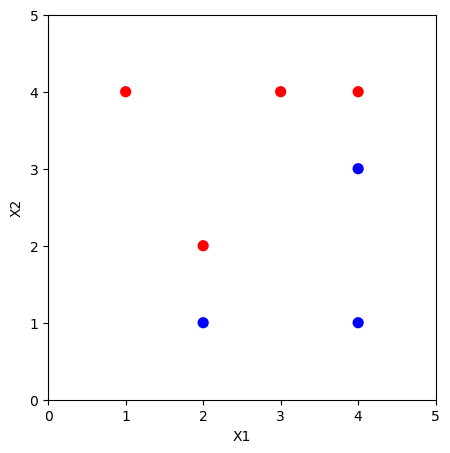

In [20]:
# Create toy data set
toy_df = pd.DataFrame({
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "Y": ["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"],
})

# Plot the observations 
def plot_points(ax):
    ax.scatter(toy_df["X1"], toy_df["X2"], c=toy_df["Y"].str.lower(), s=50)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)

fig, ax = plt.subplots(figsize=(5, 5))
plot_points(ax)
plt.show()

### (b)

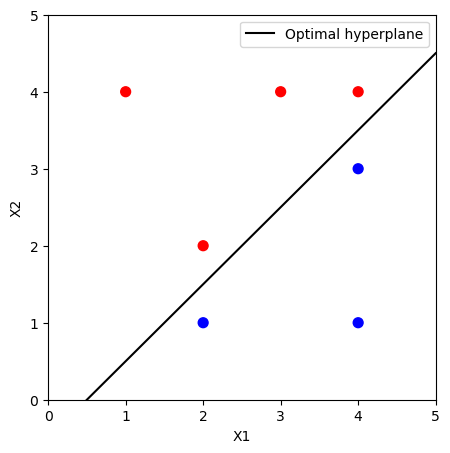

In [21]:
x1_line = np.array([0, 5])
fig, ax = plt.subplots(figsize=(5, 5))
plot_points(ax)
ax.plot(x1_line, x1_line - 0.5, "k-",label="Optimal hyperplane")
ax.legend()
plt.show()

**b answer** 

The closest Red observations, (2, 2) and (4, 4), lie on $X_2 = X_1$, and the closest Blue observations, (2, 1) and (4, 3), lie on $X_2 = X_1 - 1$. Therefore, the optimal separating hyperplane is $0.5 - X_1 + X_2 = 0$

### (c)

**c answer** 

Classify to Red if $0.5 - X_1 + X_2 > 0$, and classify to Blue otherwise. $\beta_0 = 0.5$, $\beta_1 = -1$, and $\beta_2 = 1$.

### (d)

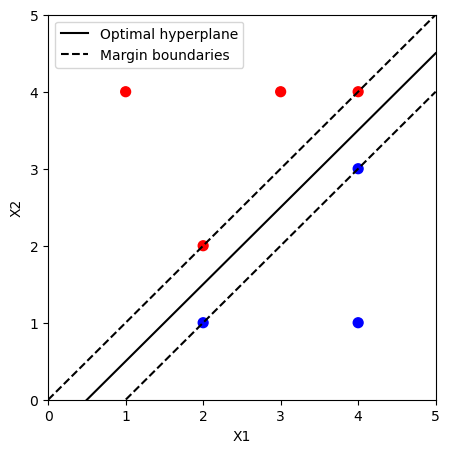

In [22]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_points(ax)
ax.plot(x1_line, x1_line - 0.5, "k-", label="Optimal hyperplane")
ax.plot(x1_line, x1_line, "k--", label="Margin boundaries")
ax.plot(x1_line, x1_line - 1, "k--")
ax.legend()
plt.show()

### (e)

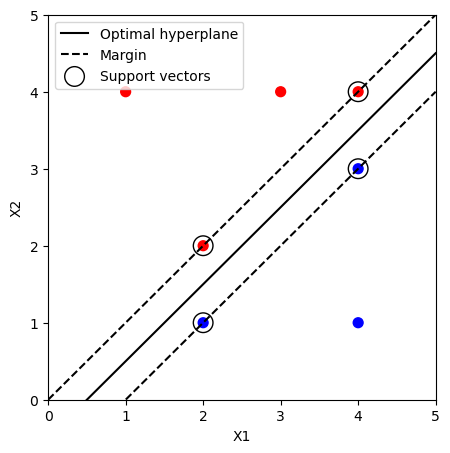

In [23]:
support_vectors = toy_df.loc[[1, 2, 4, 5]]

# circle the support vectors
fig, ax = plt.subplots(figsize=(5, 5))
plot_points(ax)
ax.plot(x1_line, x1_line - 0.5, "k-", label="Optimal hyperplane")
ax.plot(x1_line, x1_line, "k--", label="Margin")
ax.plot(x1_line, x1_line - 1, "k--")
ax.scatter(support_vectors["X1"], support_vectors["X2"], s=200, facecolors="none", edgecolors="k", label="Support vectors")
ax.legend()
plt.show()

### (f)

**f answer** 

The seventh observation (4, 1) is not a support vector. The maximal margin hyperplane depends only on the support vectors, so a slight movement of this observation does not change the hyperplane.

### (g)

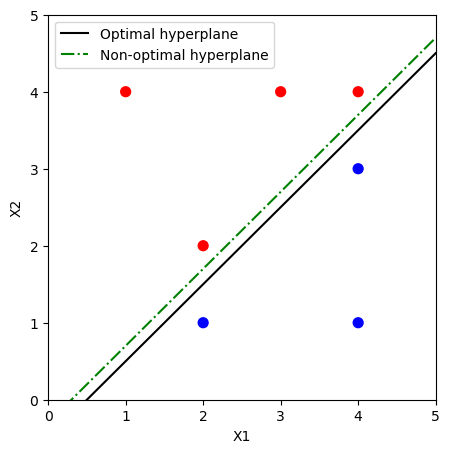

In [24]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_points(ax)
ax.plot(x1_line, x1_line - 0.5, "k-", label="Optimal hyperplane")
ax.plot(x1_line, x1_line - 0.3, "g-.", label="Non-optimal hyperplane")
ax.legend()
plt.show()

**g answer** 

The equation for this hyperplane is $0.3 - X_1 + X_2 = 0$.


### (h)

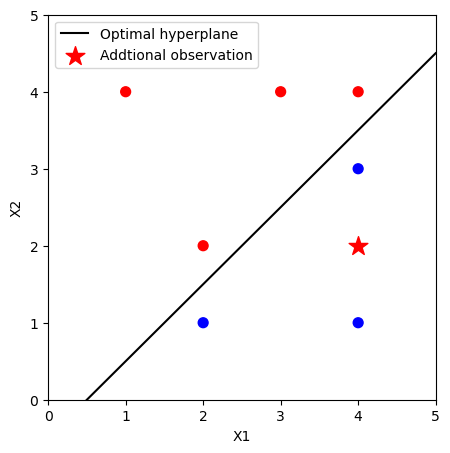

In [25]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_points(ax)
ax.plot(x1_line, x1_line - 0.5, "k-", label="Optimal hyperplane")
ax.scatter(4, 2, c="red", marker="*", s=200, label="Addtional observation")
ax.legend()
plt.show()